# Limited-label ConvNeXt transfer and robustness
Fine-tune a modern ImageNet encoder using the same 5,000 fitting labels per seed,
plus 2,000 validation and 3,000 calibration labels in disjoint partitions. The local
label-role total is 10,000. Stratified benchmark sampling uses available class
annotations; this is not a total annotation-acquisition claim.
[Measured comparisons](../docs/modern_results.md).
Resizing 32px data to 128px supplies no additional observed information.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

from io import BytesIO
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, display
def preview(path):
    # Compressed display preview; full-resolution scientific figures remain in assets.
    with PILImage.open(path) as picture:
        picture.thumbnail((760,760))
        buffer = BytesIO()
        picture.convert('RGB').save(buffer,format='JPEG',quality=90)
    display(NotebookImage(data=buffer.getvalue()))

In [2]:
m = evidence('modern_vision')
pd.DataFrame([{k:v for k,v in r.items() if not isinstance(v,list)} for r in m['rows']])

,accuracy,raw_nll,nll,temperature,set_coverage,set_size,model,seed,labels,best_epoch,gaussian_noise_accuracy
0,0.9614,0.201944,0.145867,0.670702,0.9024,0.9143,convnext_tiny_finetuned,0,5000,11,0.5503
1,0.9690,0.189476,0.124362,0.631851,0.9035,0.9120,convnext_tiny_finetuned,1,5000,26,0.5345
2,0.9692,0.200479,0.126027,0.624287,0.9122,0.9228,convnext_tiny_finetuned,2,5000,34,0.6959


In [3]:
accuracy = np.array([r['accuracy'] for r in m['rows']])
print('Accuracy mean and descriptive training-seed SD:',accuracy.mean(),accuracy.std(ddof=1))
pd.DataFrame([r['per_class_accuracy'] for r in m['rows']],index=[0,1,2],
             columns=['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck'])

Accuracy mean and descriptive training-seed SD: 0.9665333333333334 0.0044467216388405706


,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
0,0.971,0.991,0.958,0.932,0.948,0.933,0.986,0.964,0.987,0.944
1,0.975,0.978,0.961,0.915,0.972,0.951,0.990,0.979,0.988,0.981
2,0.987,0.991,0.970,0.930,0.957,0.937,0.988,0.982,0.983,0.967


## Confirm checkpoint selection
Mixup and label smoothing affect the training objective, while unsmoothed validation
NLL chooses checkpoints. Temperature then uses separate probability-calibration
labels. Test accuracy never chooses an epoch or a temperature.

In [4]:
for curve in m['curves']:
    best = min(curve['history'],key=lambda r:r['validation_nll'])
    assert best['epoch']==curve['best_epoch']
print('Every selected epoch minimizes its recorded validation NLL.')

Every selected epoch minimizes its recorded validation NLL.


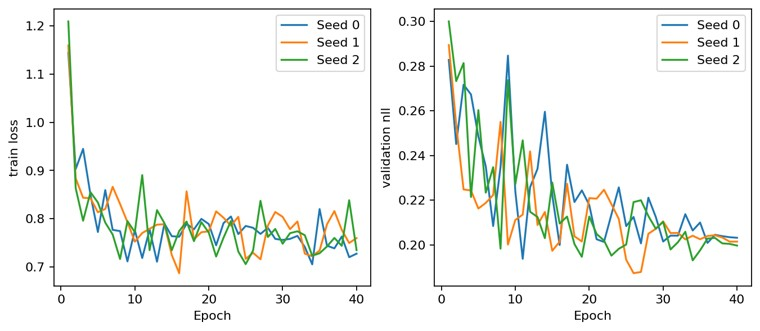

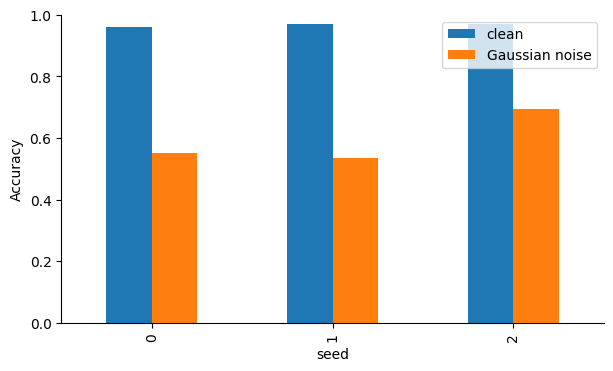

In [5]:
from IPython.display import Image,display
preview(root/'assets/modern_vision_training.png')
pd.DataFrame([{'seed':r['seed'],'clean':r['accuracy'],'Gaussian noise':r['gaussian_noise_accuracy']}
              for r in m['rows']]).set_index('seed').plot.bar(ylim=(0,1),ylabel='Accuracy')
plt.show()

## Worked answer
Why does high clean accuracy coexist with poor corrupted accuracy? Ordinary
fine-tuning optimizes the training distribution, and probability calibration does
not train invariance to corruption. This example establishes a strong practical
transfer baseline with a measurable weakness. It does not attribute all gains to
the ConvNeXt architecture, since ImageNet pretraining is additional exposure.

## Class errors and confidence
Pair predictions on identical official test examples. Intervals condition on the fitted models. Inspect all three confusion matrices rather than selecting the most favorable seed.

In [6]:
analysis = json.loads((root/'results/reference/modern_vision/diagnostics.json').read_text())
pd.DataFrame(analysis['paired'])

,seed,comparison,difference,ci95,repeats,unit
0,0,ConvNeXt fine-tuning minus imagenet_resnet18 NLL,-0.319566,"[-0.3375666815778315, -0.30071894578536273]",1000,test example
1,0,ConvNeXt fine-tuning minus supervised_lowlabel...,-0.587302,"[-0.6091984921201793, -0.5624018965918857]",1000,test example
2,0,ConvNeXt fine-tuning minus contrastive_encoder...,-0.807438,"[-0.8321268343842988, -0.7838932894816462]",1000,test example
3,1,ConvNeXt fine-tuning minus imagenet_resnet18 NLL,-0.345922,"[-0.36562231940560846, -0.32715937528866124]",1000,test example
4,1,ConvNeXt fine-tuning minus supervised_lowlabel...,-0.629787,"[-0.654950778868857, -0.6065305888714637]",1000,test example
5,1,ConvNeXt fine-tuning minus contrastive_encoder...,-0.835736,"[-0.8606734205772837, -0.8130765189278522]",1000,test example
6,2,ConvNeXt fine-tuning minus imagenet_resnet18 NLL,-0.339990,"[-0.3584958286902189, -0.3229146595324812]",1000,test example
7,2,ConvNeXt fine-tuning minus supervised_lowlabel...,-0.616591,"[-0.6398869362807604, -0.5946547238272897]",1000,test example
8,2,ConvNeXt fine-tuning minus contrastive_encoder...,-0.819617,"[-0.8447756759062346, -0.7951893456250351]",1000,test example


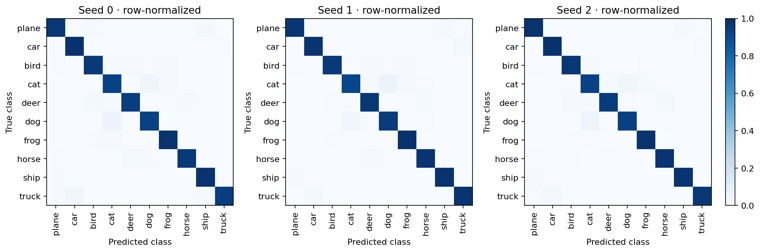

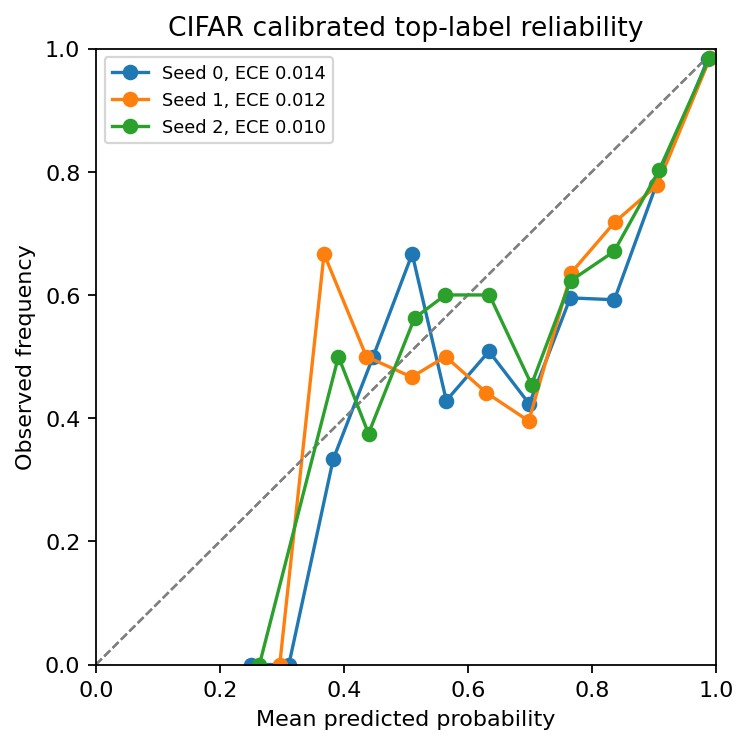

In [7]:
preview(root/'assets/modern_vision_confusion.png')
preview(root/'assets/modern_vision_reliability.png')

## Deployable prediction sets
CUDA and CPU use separate precision-bound calibration metadata. All three checkpoints retain their original independent partitions. Empty sets are explicit; singleton accuracy is descriptive, with no conditional guarantee.

In [8]:
calibration = json.loads((root/'results/reference/modern_vision/cifar_calibration_audit.json').read_text())
assert calibration['status']=='passed' and len(calibration['rows'])==6
pd.DataFrame(calibration['rows'])[['seed','profile','temperature','set_coverage','set_size','empty_set_rate','singleton_accuracy']]

,seed,profile,temperature,set_coverage,set_size,empty_set_rate,singleton_accuracy
0,0,cuda_bfloat16,0.670702,0.9024,0.9143,0.0857,0.986985
1,0,cpu_float32,0.670942,0.9038,0.9159,0.0841,0.986789
2,1,cuda_bfloat16,0.631851,0.9035,0.9120,0.0880,0.990680
3,1,cpu_float32,0.630947,0.9035,0.9121,0.0879,0.990571
4,2,cuda_bfloat16,0.624287,0.9122,0.9228,0.0772,0.988513
5,2,cpu_float32,0.624375,0.9104,0.9210,0.0790,0.988491


In [9]:
for row in calibration['rows']:
    stem = f"{row['profile']}_{row['seed']}"
    with np.load(root/f'assets/source_data/modern_vision_cifar_calibration_{stem}.npz') as saved:
        q = np.sort(saved['cal_scores'])[int(np.ceil((len(saved['cal_scores'])+1)*0.9))-1]
        assert np.isclose(q,row['cutoff'])
        sets = 1-saved['p'] <= q
        assert np.isclose(sets[np.arange(len(saved['y'])),saved['y']].mean(),row['set_coverage'])
        assert np.isclose((sets.sum(1)==0).mean(),row['empty_set_rate'])
print('All six cutoffs, test coverages and empty-set rates independently reproduced.')

All six cutoffs, test coverages and empty-set rates independently reproduced.
